# 01 — Data audit and exploratory analysis

Audits the primary Fraud Oracle benchmark, quantifies imbalance, checks missingness and identifier leakage, and describes the auxiliary evidence datasets without joining unrelated records.

**Reproducibility rule:** outputs below are generated from the untouched held-out test set or from validation/CV reports; no test result is used to fit the model or choose thresholds.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, roc_curve, auc,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
PUB = ROOT / "publication"
FIGURES = PUB / "figures"
TABLES = PUB / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GOLD, RED, GREEN, GREY = "#1f4e79", "#d89b2b", "#b03a2e", "#2e7d32", "#6b7280"

In [2]:
df = pd.read_csv(ROOT / "fraud_oracle.csv")
target = "FraudFound_P"
summary = pd.DataFrame({
    "measure": ["rows", "columns", "fraud cases", "non-fraud cases", "fraud prevalence", "duplicate rows", "missing cells", "unique policy numbers"],
    "value": [len(df), df.shape[1], int(df[target].sum()), int((1-df[target]).sum()), float(df[target].mean()), int(df.duplicated().sum()), int(df.isna().sum().sum()), int(df["PolicyNumber"].nunique())],
})
summary

,measure,value
0,rows,15420.000000
1,columns,33.000000
2,fraud cases,923.000000
3,non-fraud cases,14497.000000
4,fraud prevalence,0.059857
5,duplicate rows,0.000000
6,missing cells,0.000000
7,unique policy numbers,15420.000000


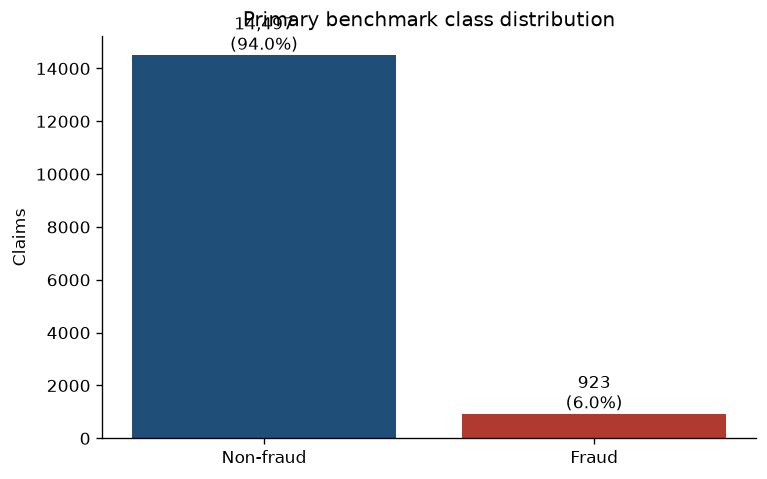

In [3]:
summary.to_csv(TABLES / "table_01_dataset_audit.csv", index=False)
(TABLES / "table_01_dataset_audit.tex").write_text(summary.to_latex(index=False, escape=True, float_format="%.4f"), encoding="utf-8")

counts = df[target].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 4.1))
bars = ax.bar(["Non-fraud", "Fraud"], counts.values, color=[BLUE, RED])
ax.set_ylabel("Claims")
ax.set_title("Primary benchmark class distribution")
for b, v in zip(bars, counts.values): ax.text(b.get_x()+b.get_width()/2, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
fig.tight_layout(); fig.savefig(FIGURES / "figure_01_class_distribution.png", bbox_inches="tight"); plt.show()

In [4]:
aux = pd.DataFrame([
    ["Fraud Oracle", 15420, "structured claims", "FraudFound_P", "Primary fraud benchmark"],
    ["Comprehensive Car Damage", 2300, "vehicle images", "six damage/view classes", "Damage recognition only"],
    ["AI-generated E-commerce Images", 6031, "synthetic images + annotations", "12 issue classes", "Evidence prototype only"],
    ["INSURBIAS", 1388, "images + synthetic narratives + metadata", "condition/severity; no verified fraud target", "Counterfactual fairness/evidence audit only"],
])
aux.columns = ["dataset", "records", "modalities", "available labels", "permitted role"]
aux.to_csv(TABLES / "table_02_dataset_roles.csv", index=False)
(TABLES / "table_02_dataset_roles.tex").write_text(aux.to_latex(index=False, escape=True), encoding="utf-8")
aux

,dataset,records,modalities,available labels,permitted role
0,Fraud Oracle,15420,structured claims,FraudFound_P,Primary fraud benchmark
1,Comprehensive Car Damage,2300,vehicle images,six damage/view classes,Damage recognition only
2,AI-generated E-commerce Images,6031,synthetic images + annotations,12 issue classes,Evidence prototype only
3,INSURBIAS,1388,images + synthetic narratives + metadata,condition/severity; no verified fraud target,Counterfactual fairness/evidence audit only
